# **Regression Practice Notebook**

This notebook contains practice questions for three regression techniques:
1. Simple Linear Regression
2. Multiple Linear Regression
3. Gradient Boosting Regressor

Each section uses a different dataset. Write your code in the empty cells below each question.

## **Section 1: Simple Linear Regression**

**Dataset:** `study_hours_exam_score.csv`
**Shape:** (1000, 2)
**Columns:** `StudyHours` (input), `ExamScore` (output)

**Q1.** Import the required libraries (`pandas`, `matplotlib.pyplot`) and load `study_hours_exam_score.csv` into a DataFrame. Display the first 5 rows.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv("study_hours_exam_score.csv")
print(df.head())

   StudyHours  ExamScore
0        5.59      56.64
1        8.92      74.03
2        1.00      25.87
3        4.33      48.35
4        2.61      25.43


**Q2.** Check the shape of the dataset and confirm there are no missing values.

In [2]:
print(df.shape)

print(df.isnull().sum())

(1000, 2)
StudyHours    0
ExamScore     0
dtype: int64


**Q3.** Create a scatter plot to visualize the relationship between `StudyHours` and `ExamScore`.

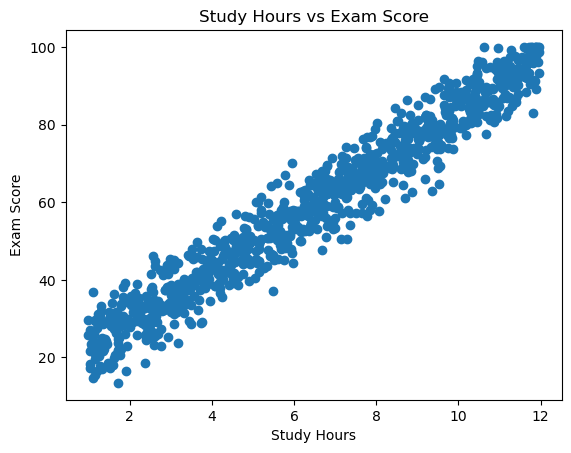

In [3]:
plt.scatter(df["StudyHours"], df["ExamScore"])

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Study Hours vs Exam Score")

plt.show()

**Q4.** Separate the dataset into an independent variable `X` and a dependent variable `y`.

In [4]:
X = df[["StudyHours"]]

y = df[["ExamScore"]]

print(X.head())
print(y.head())

   StudyHours
0        5.59
1        8.92
2        1.00
3        4.33
4        2.61
   ExamScore
0      56.64
1      74.03
2      25.87
3      48.35
4      25.43


**Q5.** Split the data into training and testing sets.

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(800, 1)
(200, 1)
(800, 1)
(200, 1)


**Q6.** Build a Simple Linear Regression model and train it using the training data.

In [6]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model Training Completed")

Model Training Completed


**Q7.** Print the slope and intercept of the fitted regression line.

In [7]:
print("Slope:", model.coef_)

print("Intercept:", model.intercept_)

Slope: [[6.76433115]]
Intercept: [15.48860135]


**Q8.** Predict `ExamScore` values for the test set.

In [8]:
y_pred = model.predict(X_test)

print(y_pred)

[[66.49165821]
 [68.72388749]
 [95.8488554 ]
 [61.55369647]
 [69.40032061]
 [91.7226134 ]
 [66.96516139]
 [39.29904699]
 [69.80618047]
 [82.3201931 ]
 [53.23356916]
 [91.24911022]
 [84.41713576]
 [87.52872808]
 [59.45675382]
 [48.63382398]
 [87.73165802]
 [47.551531  ]
 [94.02248599]
 [85.63471536]
 [38.62261388]
 [63.24477926]
 [24.21458853]
 [27.12325093]
 [51.61012968]
 [66.82987477]
 [61.48605316]
 [61.35076654]
 [25.49981145]
 [38.41968395]
 [74.60885559]
 [77.85573454]
 [76.50286831]
 [39.23140368]
 [48.70146729]
 [68.11509769]
 [67.91216775]
 [79.81739057]
 [90.03153061]
 [74.33828234]
 [62.70363277]
 [89.49038412]
 [41.39598965]
 [41.1254164 ]
 [35.7815948 ]
 [53.97764559]
 [57.76567103]
 [81.77904661]
 [31.58770949]
 [56.68337805]
 [58.30681752]
 [71.97076644]
 [86.10821854]
 [72.24133969]
 [73.79713585]
 [29.55841014]
 [37.33739096]
 [53.43649909]
 [46.94274119]
 [73.45891929]
 [50.39255008]
 [58.84796401]
 [57.08923792]
 [90.64032041]
 [37.67560752]
 [88.94923762]
 [33.41407

**Q9.** Calculate the model's training score and testing score.

In [9]:
train_score = model.score(X_train, y_train)

test_score = model.score(X_test, y_test)

print("Training Score:", train_score)

print("Testing Score:", test_score)

Training Score: 0.9477856897467457
Testing Score: 0.9477658765932853


**Q10.** Calculate the error between the actual and predicted values for the test set.

In [10]:
error = y_test - y_pred

print(error)

print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))

print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

     ExamScore
521  -2.601658
737   0.556113
740   4.151145
660   0.446304
411   9.439679
..         ...
408  10.729169
332  -9.307901
208  -4.411467
613  -5.293314
78    2.873692

[200 rows x 1 columns]


NameError: name 'mean_absolute_error' is not defined

**Q11.** Plot the actual test values and the predicted values, along with the best fit line.

Index(['StudyHours'], dtype='object')


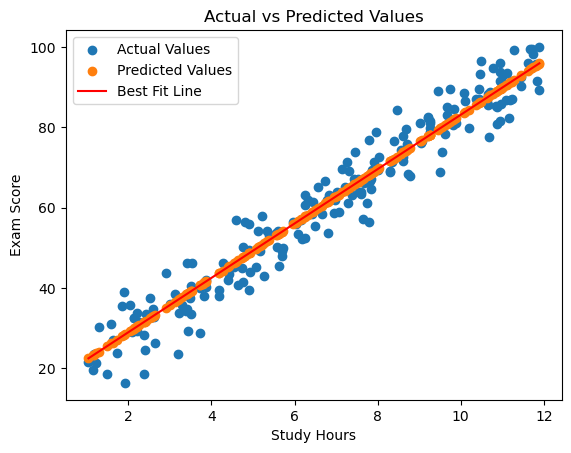

In [12]:
print(X_test.columns)

X_sorted = X_test.sort_values(by="StudyHours")

y_sorted = model.predict(X_sorted)

plt.scatter(X_test.values.ravel(), y_test, label="Actual Values")

plt.scatter(X_test.values.ravel(), y_pred, label="Predicted Values")

plt.plot(X_sorted.values.ravel(), y_sorted, color="red", label="Best Fit Line")

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.title("Actual vs Predicted Values")

plt.legend()

plt.show()

## **Section 2: Multiple Linear Regression**

**Dataset:** `car_price_multiple.csv`
**Shape:** (5000, 4)
**Columns:** `EngineSize_L`, `Mileage_km`, `CarAge_years` (inputs), `Price_USD` (output)

**Q1.** Load `car_price_multiple.csv` into a DataFrame and display its structure (`.info()` and `.describe()`).

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("car_price_multiple.csv")

print(df.info())

print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   EngineSize_L  5000 non-null   float64
 1   Mileage_km    5000 non-null   float64
 2   CarAge_years  5000 non-null   float64
 3   Price_USD     5000 non-null   float64
dtypes: float64(4)
memory usage: 156.4 KB
None
       EngineSize_L     Mileage_km  CarAge_years     Price_USD
count   5000.000000    5000.000000   5000.000000   5000.000000
mean       2.479148   99139.685200      7.535080  22119.486528
std        0.863222   58459.517416      4.326138   5432.659758
min        1.000000     514.000000      0.000000   5820.000000
25%        1.730000   49123.750000      3.800000  18313.570000
50%        2.450000   98220.500000      7.600000  22155.370000
75%        3.220000  151056.000000     11.300000  26030.527500
max        4.000000  199984.000000     15.000000  37912.650000


**Q2.** Confirm the dataset has no missing or duplicate values.

In [5]:
print("Total Missing Values:", df.isnull().sum())

print("Total Duplicate Values:", df.duplicated().sum())

Total Missing Values: EngineSize_L    0
Mileage_km      0
CarAge_years    0
Price_USD       0
dtype: int64
Total Duplicate Values: 0


**Q3.** Separate the independent variables `X` (`EngineSize_L`, `Mileage_km`, `CarAge_years`) and the dependent variable `y` (`Price_USD`).

In [7]:
X = df[['EngineSize_L', 'Mileage_km', 'CarAge_years']]

y = df[['Price_USD']]

print(X.head())

print(y.head())

   EngineSize_L  Mileage_km  CarAge_years
0          2.31    118374.0           0.7
1          1.08    134437.0           3.9
2          2.65      6908.0          12.9
3          2.31     66733.0          12.7
4          2.26    143137.0           4.2
   Price_USD
0   27190.09
1   15215.58
2   22430.60
3   19368.15
4   22013.22


**Q4.** Split the dataset into training and testing sets using an 80-20 split.

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape)

print(X_test.shape)

print(y_train.shape)

print(y_test.shape)

(4000, 3)
(1000, 3)
(4000, 1)
(1000, 1)


**Q5.** Build and train a Multiple Linear Regression model on the training data.

In [9]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model Training Completed")

Model Training Completed


**Q6.** Predict `Price_USD` for the test set.

In [12]:
y_pred = model.predict(X_test)

print("Actual Price:")
print(y_test.head())

print("Predicted Price:")
print(y_pred[:2])

Actual Price:
      Price_USD
1501   10994.50
2586   24126.83
2653   31662.80
1055   27630.77
705    20854.63
Predicted Price:
[[11071.80498329]
 [24669.9088146 ]]


**Q7.** Print the model's coefficients and intercept. Identify which feature has the strongest influence based on coefficient magnitude.

In [13]:
print("Coefficients:", model.coef_)

print("Intercept:", model.intercept_)

features = X.columns

for feature, coef in zip(features, model.coef_):
    print(feature, ":", coef)

strongest_feature = features[np.argmax(np.abs(model.coef_))]

print("Strongest Influencing Feature:", strongest_feature)

Coefficients: [[ 3.23117258e+03 -4.49990975e-02 -8.41692346e+02]]
Intercept: [24907.81041774]
EngineSize_L : [ 3.23117258e+03 -4.49990975e-02 -8.41692346e+02]
Strongest Influencing Feature: EngineSize_L


**Q8.** Calculate the training score and testing score of the model.

In [14]:
train_score = model.score(X_train, y_train)

test_score = model.score(X_test, y_test)

print("Training Score:", train_score)

print("Testing Score:", test_score)

Training Score: 0.9216354020818603
Testing Score: 0.9290167145655365


**Q9.** Compute MAE, MSE, RMSE, and R² score for the model's predictions.

In [15]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

MAE = mean_absolute_error(y_test, y_pred)

MSE = mean_squared_error(y_test, y_pred)

RMSE = np.sqrt(MSE)

R2 = r2_score(y_test, y_pred)

print("MAE:", MAE)

print("MSE:", MSE)

print("RMSE:", RMSE)

print("R2 Score:", R2)

MAE: 1191.0160902619116
MSE: 2219821.1724059866
RMSE: 1489.9064307552962
R2 Score: 0.9290167145655365


**Q10.** Create a scatter plot of Actual vs Predicted prices, with a diagonal reference line representing perfect predictions.

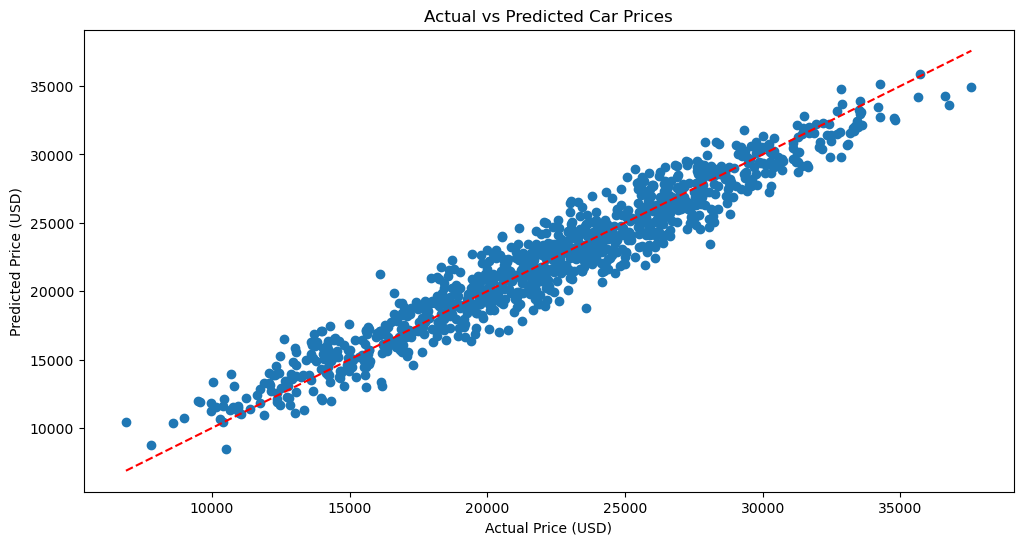

In [17]:
plt.figure(figsize=(12, 6))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)

plt.xlabel("Actual Price (USD)")

plt.ylabel("Predicted Price (USD)")

plt.title("Actual vs Predicted Car Prices")

plt.show()

## **Section 3: Gradient Boosting Regressor**

**Dataset:** `laptop_price_gbr.csv`
**Shape:** (10000, 6)
**Columns:** `RAM_GB`, `Storage_GB`, `ScreenSize_inch`, `Weight_kg`, `BatteryLife_hrs` (inputs), `Price_USD` (output)

**Q1.** Load `laptop_price_gbr.csv` into a DataFrame. Check its shape and data types.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("laptop_price_gbr.csv")

print(df.shape)
print(df.dtypes)
print(df.head())

(10000, 6)
RAM_GB               int64
Storage_GB           int64
ScreenSize_inch    float64
Weight_kg          float64
BatteryLife_hrs    float64
Price_USD          float64
dtype: object
   RAM_GB  Storage_GB  ScreenSize_inch  Weight_kg  BatteryLife_hrs  Price_USD
0      16        2048             13.0       1.17             16.0    1365.85
1       4         256             12.6       2.44              7.5     371.03
2       8        1024             16.0       1.60             13.5     686.07
3      32        1024             14.1       2.68             10.8    1164.84
4       4        1024             15.2       1.37              9.7     622.77


**Q2.** Confirm the dataset has no missing values.

In [2]:
print(df.isnull().sum())

RAM_GB             0
Storage_GB         0
ScreenSize_inch    0
Weight_kg          0
BatteryLife_hrs    0
Price_USD          0
dtype: int64


**Q3.** Separate the independent variables `X` and the dependent variable `y` (`Price_USD`).

In [3]:
X = df.drop('Price_USD', axis=1)
y = df['Price_USD']

print(X.head())
print(y.head())

   RAM_GB  Storage_GB  ScreenSize_inch  Weight_kg  BatteryLife_hrs
0      16        2048             13.0       1.17             16.0
1       4         256             12.6       2.44              7.5
2       8        1024             16.0       1.60             13.5
3      32        1024             14.1       2.68             10.8
4       4        1024             15.2       1.37              9.7
0    1365.85
1     371.03
2     686.07
3    1164.84
4     622.77
Name: Price_USD, dtype: float64


**Q4.** Split the dataset into training and testing sets (80-20 split, `random_state=42`).

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape)
print(X_test.shape)

(8000, 5)
(2000, 5)


**Q5.** Build a `GradientBoostingRegressor` model with `n_estimators=100`, `learning_rate=0.1`, and `max_depth=3`. Train it on the training data.

In [9]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gbr.fit(X_train, y_train)

print("Model trained successfully")

Model trained successfully


**Q6.** Predict `Price_USD` for the test set.

In [10]:

y_pred = gbr.predict(X_test)

results = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': y_pred
})

display(results.head(10))

,Actual Price,Predicted Price
6252,250.00,300.478370
4684,1778.81,1577.020053
1731,441.13,534.852205
4742,575.67,686.221199
4521,1197.15,1119.443757
6340,1432.40,1416.944960
576,353.70,435.475152
5202,626.75,613.739058
6363,1052.67,1033.570287
439,580.58,578.738193


**Q7.** Evaluate the model using MAE, MSE, RMSE, and R² score.

In [11]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

MAE: 48.85
MSE: 3724.39
RMSE: 61.03
R2 Score: 0.9842


**Q8.** Create a scatter plot comparing Actual vs Predicted prices, with a diagonal reference line for perfect predictions.

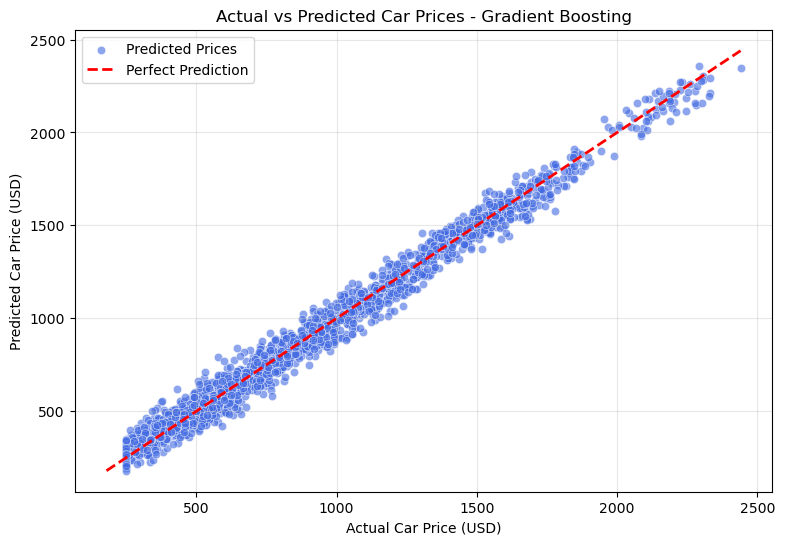

In [12]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    color='royalblue',
    alpha=0.6,
    label='Predicted Prices'
)

min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    color='red',
    linestyle='--',
    linewidth=2,
    label='Perfect Prediction'
)

plt.xlabel("Actual Car Price (USD)")
plt.ylabel("Predicted Car Price (USD)")
plt.title("Actual vs Predicted Car Prices - Gradient Boosting")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Q9.** Extract and plot the feature importances from the trained model. Which feature contributes most to predicting `Price_USD`?

           Feature  Importance
0           RAM_GB    0.686909
1       Storage_GB    0.276293
3        Weight_kg    0.014767
4  BatteryLife_hrs    0.013139
2  ScreenSize_inch    0.008891


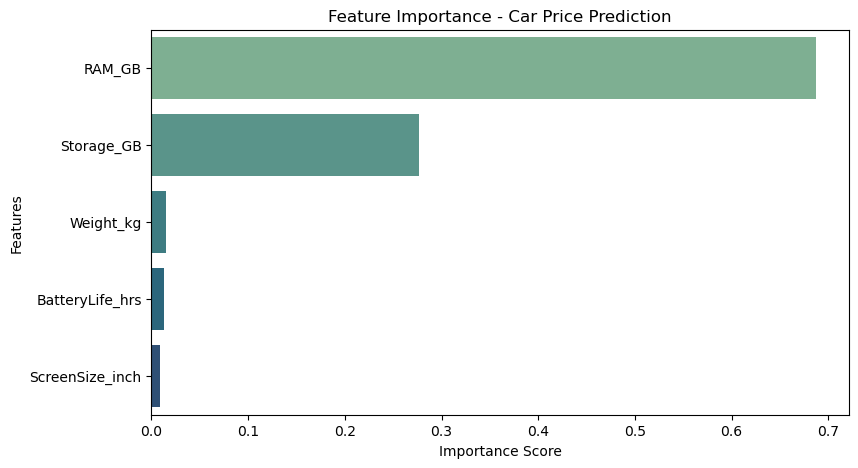

In [13]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': gbr.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='crest',
    legend=False
)

plt.title("Feature Importance - Car Price Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

**Q10.** Compare the R² score of this model with the Multiple Linear Regression model from Section 2 (conceptually) — which type of model would you expect to perform better on non-linear relationships, and why?

Gradient Boosting Regressor is generally expected to perform better than Multiple Linear Regression when the dataset contains complex and non-linear relationships.
- Multiple Linear Regression: Assumes a linear relationship between input features and the target variable.
- Gradient Boosting Regressor: Can capture complex and non-linear relationships by combining multiple decision trees.
Conclusion: Gradient Boosting Regressor is more suitable for datasets with non-linear patterns, while Multiple Linear Regression is suitable for simpler linear relationships.